#### Goal: Forcast end of training time for 1 epoch

In [2]:
import re
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import time

Average time per file: 26.27 seconds
Estimated time remaining: 1 days 00:04:50.153010859


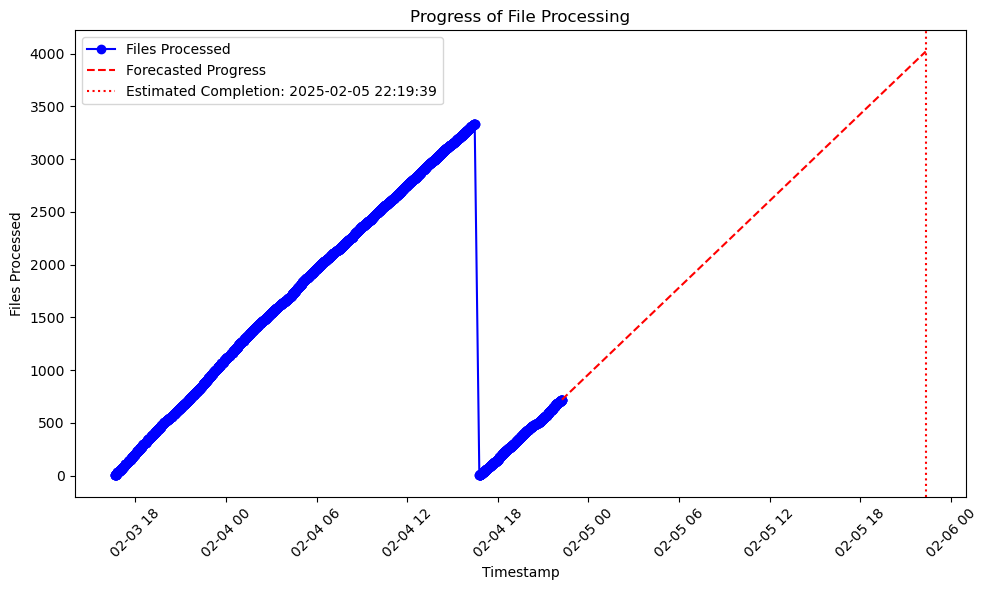

In [3]:
log_file_path = '../finetune/sbatchlogs/checkpoint/cds_exp1/train_state.log'
log_lines = []

with open(log_file_path, 'r') as f:
    log_lines = f.readlines()

log_pattern = r"(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - INFO - (\d+)/4019 - .*Fully used (.+) for training"
log_data = []
for line in log_lines:
    match = re.search(log_pattern, line)
    if match:
        timestamp_str = match.group(1)
        file_number = int(match.group(2))
        file_path = match.group(3)
        
        timestamp = datetime.strptime(timestamp_str, '%Y-%m-%d %H:%M:%S')
        log_data.append([timestamp, file_number, file_path])

df = pd.DataFrame(log_data, columns=['timestamp', 'file_number', 'file_path'])
df.head()

# ---

# time taken per file
df['time_diff'] = df['timestamp'].diff().dt.total_seconds()
df['time_diff'] = df['time_diff'].fillna(0)

# average time per file
avg_time_per_file = df['time_diff'].mean()

# Estimate remaining time
remaining_files = 4019 - df['file_number'].iloc[-1]
remaining_time_seconds = remaining_files * avg_time_per_file
remaining_time = pd.to_timedelta(remaining_time_seconds, unit='s')

# forecasted time left
print(f"Average time per file: {avg_time_per_file:.2f} seconds")
print(f"Estimated time remaining: {remaining_time}")

# ---

# Plot progress over time
plt.figure(figsize=(10, 6))
plt.plot(df['timestamp'], df['file_number'], label="Files Processed", marker='o', color='b')
plt.xlabel('Timestamp')
plt.ylabel('Files Processed')
plt.title('Progress of File Processing')

# Forecast the line to the estimated completion point
last_timestamp = df['timestamp'].iloc[-1]
forecasted_completion_time = last_timestamp + remaining_time

# Add a forecast line
forecast_times = pd.date_range(start=last_timestamp, periods=remaining_files + 1, freq=pd.to_timedelta(avg_time_per_file, unit='s'))
plt.plot(forecast_times, range(df['file_number'].iloc[-1], 4020), linestyle='--', color='r', label="Forecasted Progress")

# Display the estimated completion time
plt.axvline(forecasted_completion_time, color='r', linestyle=':', label=f"Estimated Completion: {forecasted_completion_time.strftime('%Y-%m-%d %H:%M:%S')}")
plt.legend()

# Show plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [1]:
(int(3333/50) * 50) - 1 + 1
(int(3405/50) * 50) - 1 + 1


3400

In [42]:
14387+10656+13162

38205

In [43]:
14387*3

43161

In [50]:
87-65

22

In [ ]:
16:46-17:34

In [58]:
(60+46) - (120+34)

-48

In [59]:
(60+40) - (120+17)

-37

---

In [13]:
def update_progress_visualization(log_file_path, interval=60):
    plt.figure(figsize=(10, 6))
    #while True:
    log_lines = []
    with open(log_file_path, 'r') as f:
        log_lines = f.readlines()

    log_pattern = r"(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) - INFO - (\d+)/4019 - .*Fully used (.+) for training"
    log_data = []
    for line in log_lines:
        match = re.search(log_pattern, line)
        if match:
            timestamp_str = match.group(1)
            file_number = int(match.group(2))
            file_path = match.group(3)

            timestamp = datetime.strptime(timestamp_str, '%Y-%m-%d %H:%M:%S')
            log_data.append([timestamp, file_number, file_path])

    df = pd.DataFrame(log_data, columns=['timestamp', 'file_number', 'file_path'])
    df['time_diff'] = df['timestamp'].diff().dt.total_seconds()
    df['time_diff'] = df['time_diff'].fillna(0)

    avg_time_per_file = df['time_diff'].mean()
    remaining_files = 4019 - df['file_number'].iloc[-1]
    remaining_time_seconds = remaining_files * avg_time_per_file
    remaining_time = pd.to_timedelta(remaining_time_seconds, unit='s')
    print(f"Average time per file: {avg_time_per_file:.2f} seconds")
    print(f"Estimated time remaining: {remaining_time}")

    plt.clf()
    plt.plot(df['timestamp'], df['file_number'], label="Files Processed", marker='o', color='b')
    plt.xlabel('Timestamp')
    plt.ylabel('Files Processed')
    plt.title('Progress of File Processing')

    # forecast
    last_timestamp = df['timestamp'].iloc[-1]
    forecasted_completion_time = last_timestamp + remaining_time
    forecast_times = pd.date_range(start=last_timestamp, periods=remaining_files + 1, freq=pd.to_timedelta(avg_time_per_file, unit='s'))
    plt.plot(forecast_times, range(df['file_number'].iloc[-1], 4020), linestyle='--', color='r', label="Forecasted Progress")
    plt.axvline(forecasted_completion_time, color='r', linestyle=':', label=f"Estimated Completion: {forecasted_completion_time.strftime('%Y-%m-%d %H:%M:%S')}")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.draw()
    plt.pause(interval)

Average time per file: 22.96 seconds
Estimated time remaining: 1 days 00:13:19.330316742


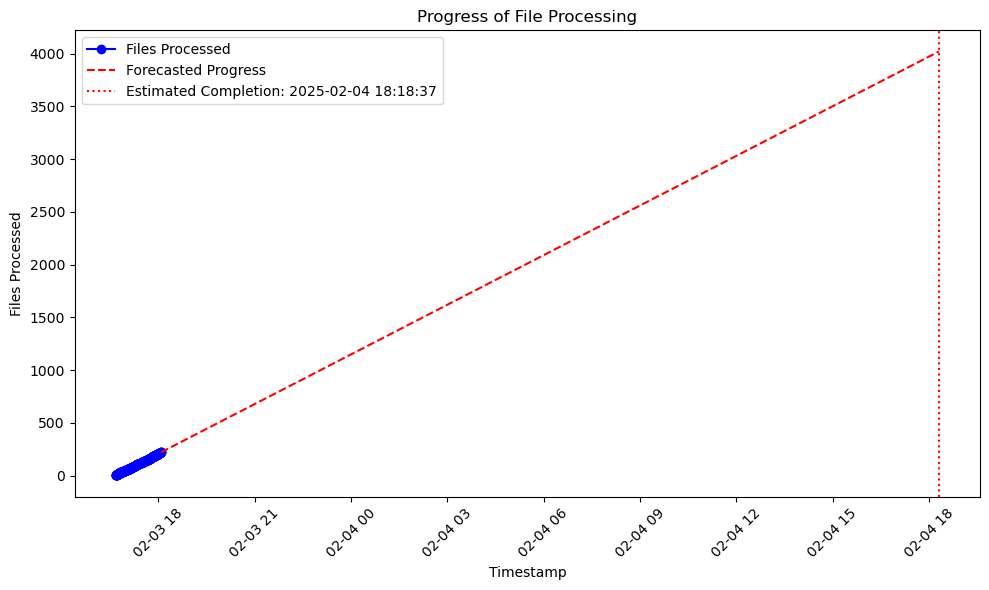

KeyboardInterrupt: 

In [14]:
update_progress_visualization(log_file_path='../finetune/sbatchlogs/checkpoint/cds_exp1/train_state.log', interval=120)

In [ ]:
# END